# 03 · Baseline 2: zero-shot prompting

The second baseline asks the question every LLM project should answer first: **can the model already do this if we just ask it?** If zero-shot prompting were as good as fine-tuning, the fine-tuning would be wasted effort.

I use **the same model** that gets fine-tuned later, `Qwen/Qwen3-4B-Instruct-2507`. With the same model on both sides, the comparison isolates the effect of LoRA fine-tuning from the choice of model.

### How the prediction is read

Letting the model generate free text and parsing it with regexes is fragile. The model may say "Positive.", "The sentiment is positive" or switch to Arabic. Instead:

1. format the comment with the chat template and the instruction prompt,
2. run **one forward pass** and take the logits for the *next* token,
3. compare only the three tokens `negative`, `neutral` and `positive`, and softmax over them.

This always yields a valid label, gives a probability for each class, and takes one forward pass per comment instead of autoregressive generation.

In [1]:
import sys
sys.path.insert(0, "../src")

import time

import matplotlib.pyplot as plt
import pandas as pd
import torch

from darija_sentiment.config import BASE_MODEL, LABELS
from darija_sentiment.data import load_splits
from darija_sentiment.llm import USER_TEMPLATES, ZeroShotClassifier, build_prompt
from darija_sentiment.metrics import (
    bootstrap_ci, evaluate_by_script, plot_confusion, save_figure, save_metrics, save_predictions,
)

pd.set_option("display.max_colwidth", 120)
splits = load_splits()
train, val, test = splits["train"], splits["val"], splits["test"]

In [2]:
zs = ZeroShotClassifier(BASE_MODEL)
print(build_prompt(zs.tokenizer, "ya3tik saha khoya"))

<|im_start|>system
You are an expert annotator of Algerian Arabic (Darija) social-media text. Darija comments can be written in Arabic script or in Latin script (Arabizi, where digits stand for Arabic sounds: 3 = ع, 7 = ح, 9 = ق), and they often mix in French, Modern Standard Arabic and English.<|im_end|>
<|im_start|>user
Classify the overall sentiment of this YouTube comment.

- positive: praise, support, love, thanks, admiration, and religious blessings, good wishes or condolences (e.g. ربي يحفظك, الله يرحمه, rabi ykhalik)
- negative: criticism, insults, anger, mockery, sarcasm, complaints, political protest, disappointment
- neutral: plain questions or requests, factual statements, news, and comments that express no opinion

Comment: ya3tik saha khoya

Answer with exactly one word: positive, negative, or neutral.<|im_end|>
<|im_start|>assistant



The instructions are in English on purpose. Instruction-tuned models follow English instructions most reliably, and the comment itself stays in its original script.

## Two prompt versions, chosen on the validation set

Zero-shot means no *training*, but a prompt still encodes assumptions about what each label means, and different annotators draw the lines differently. My first prompt (`v1_generic`) followed general intuition and called prayers for the dead *neutral*. The error analysis in notebook 05 showed that guess was wrong for this dataset. Checking the **training split** (never the test set) for how annotators treated a few recurring comment types:

In [3]:
patterns = {
    "condolences / prayers (يرحم, rahma, yarhm)": r"يرحم|رحمه الله|رحمة الله|y[ae]r[h7]m|rahma|ra7ma",
    "blessings (ربي يحفظ, الله يبارك, rabi ykhalik)": r"يحفظ|يبارك|يخليك|ربي يوفق|الله يوفق|rabi y|rebi y",
    "contains a question mark": r"[?؟]",
}
pd.DataFrame({
    name: train.loc[train["text"].str.contains(rx, case=False, regex=True), "label"]
              .map(dict(enumerate(LABELS))).value_counts(normalize=True).reindex(LABELS).round(2)
    for name, rx in patterns.items()
}).T.assign(n=[train["text"].str.contains(rx, case=False, regex=True).sum() for rx in patterns.values()])

label,negative,neutral,positive,n
"condolences / prayers (يرحم, rahma, yarhm)",0.20,0.15,0.65,1413
"blessings (ربي يحفظ, الله يبارك, rabi ykhalik)",0.03,0.05,0.92,2742
contains a question mark,0.34,0.60,0.06,1249


In this dataset, condolences and blessings are mostly **positive**, and questions are mostly **neutral**. The second prompt (`v2_dataset_conventions`) spells out those conventions:

In [4]:
print(USER_TEMPLATES["v2_dataset_conventions"])

Classify the overall sentiment of this YouTube comment.

- positive: praise, support, love, thanks, admiration, and religious blessings, good wishes or condolences (e.g. ربي يحفظك, الله يرحمه, rabi ykhalik)
- negative: criticism, insults, anger, mockery, sarcasm, complaints, political protest, disappointment
- neutral: plain questions or requests, factual statements, news, and comments that express no opinion

Comment: {text}

Answer with exactly one word: positive, negative, or neutral.


A quick sanity check on a few hand-written comments:

In [5]:
examples = [
    "ya3tik saha khoya, khedma mli7a bezzaf",   # well done brother, very good work
    "ربي يحفظك و يخليك لينا",                    # may God protect you and keep you for us
    "wach had l'7mar9a, rana 3yina",            # what is this nonsense, we're fed up
    "خسارة الوقت لي ضيعتو في هاد الفيديو",       # waste of the time I lost on this video
    "win rah had lblasa?",                      # where is this place?
]
pd.DataFrame(zs.predict_proba(examples), index=examples, columns=LABELS).round(3)

,negative,neutral,positive
"ya3tik saha khoya, khedma mli7a bezzaf",0.0,0.001,0.999
ربي يحفظك و يخليك لينا,0.0,0.000,1.000
"wach had l'7mar9a, rana 3yina",0.0,0.007,0.993
خسارة الوقت لي ضيعتو في هاد الفيديو,1.0,0.000,0.000
win rah had lblasa?,0.0,1.000,0.000


## Validation set: pick the prompt

Both prompts run on the validation set. The one with the higher macro-F1 is the only one that ever sees the test set.

In [6]:
val_scores = {}
for name in USER_TEMPLATES:
    start = time.time()
    val_proba = zs.predict_proba(val["text"].tolist(), template=name)
    val_scores[name] = evaluate_by_script(val.assign(pred=val_proba.argmax(1)))
    print(f"{name}: {len(val):,} comments in {time.time() - start:.0f} s")

pd.DataFrame({name: table["macro_f1"] for name, table in val_scores.items()}).round(4)

v1_generic: 4,996 comments in 171 s


v2_dataset_conventions: 4,996 comments in 328 s


,v1_generic,v2_dataset_conventions
subset,,
all,0.6243,0.6472
arabic,0.6329,0.6562
latin,0.5104,0.5281
mixed,0.7855,0.8263


In [7]:
best_template = max(val_scores, key=lambda name: val_scores[name].loc["all", "macro_f1"])
print("selected prompt:", best_template)

selected prompt: v2_dataset_conventions


The dataset-aware prompt is better on validation (0.647 vs 0.624), mostly because it stops calling blessings and condolences neutral. It is the only prompt run on the test set.

## Test set

In [8]:
start = time.time()
proba = zs.predict_proba(test["text"].tolist(), template=best_template)
seconds = time.time() - start
print(f"{len(test):,} comments in {seconds:.0f} s ({len(test) / seconds:.1f} comments/s)")

test_pred = test.assign(pred=proba.argmax(1), p_negative=proba[:, 0], p_neutral=proba[:, 1], p_positive=proba[:, 2])
by_script = evaluate_by_script(test_pred)
by_script.round(4)

4,996 comments in 326 s (15.3 comments/s)


,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,n
subset,,,,,,
all,0.6349,0.6996,0.6959,0.4097,0.7990,4996
arabic,0.6397,0.7027,0.7157,0.4059,0.7974,4306
latin,0.5686,0.6788,0.4903,0.4100,0.8055,632
mixed,0.6835,0.7200,0.5882,0.6111,0.8511,50


In [9]:
ci = bootstrap_ci(test_pred["label"], test_pred["pred"])
print(f"test macro-F1 = {by_script.loc['all', 'macro_f1']:.4f}  (95% bootstrap CI {ci[0]:.4f}–{ci[1]:.4f})")
print("prediction distribution:", test_pred["pred"].map(dict(enumerate(LABELS))).value_counts(normalize=True).round(3).to_dict())
print("true distribution:      ", test_pred["label"].map(dict(enumerate(LABELS))).value_counts(normalize=True).round(3).to_dict())

save_predictions(test_pred, "zero_shot")
save_metrics({
    "system": f"Zero-shot prompting ({BASE_MODEL})",
    "prompt": best_template,
    "val_macro_f1_by_prompt": {name: table.loc["all", "macro_f1"] for name, table in val_scores.items()},
    "val_macro_f1": val_scores[best_template].loc["all", "macro_f1"],
    "test": by_script.to_dict(orient="index"),
    "test_macro_f1_ci95": ci,
    "comments_per_second": len(test) / seconds,
}, "zero_shot")

test macro-F1 = 0.6349  (95% bootstrap CI 0.6200–0.6492)
prediction distribution: {'positive': 0.6, 'negative': 0.275, 'neutral': 0.125}
true distribution:       {'positive': 0.437, 'negative': 0.341, 'neutral': 0.223}


**Zero-shot gets 0.635 macro-F1 on test (95% CI 0.620–0.649)**, about 13 points below the TF-IDF baseline. Two problems stand out:

- **It is biased towards positive.** 60% of its predictions are positive, but only 44% of the gold labels are. Meanwhile it predicts neutral for 12.5% of comments where the true share is 22%, which gives a neutral F1 of only 0.41. Algerian comment sections are full of formulaic religious phrases and enthusiastic emoji, and the model reads many of them as praise.
- **It reads Arabizi poorly.** Negative F1 on Latin-script comments is 0.49. The sanity check above already showed it: "wach had l'7mar9a, rana 3yina" (*what is this nonsense, we're fed up*) is classified as positive with 99% confidence.

Better prompting helped a little (+2.3 points on validation), but no prompt can fully specify where 50,000 annotators' judgements draw the line between neutral and the other classes. That takes labelled data, which is what the next notebook uses.

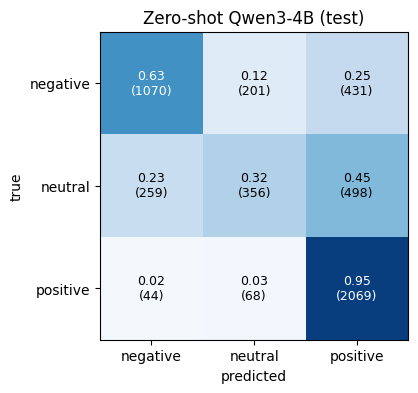

In [10]:
fig, ax = plt.subplots(figsize=(4.4, 4))
plot_confusion(test_pred["label"], test_pred["pred"], "Zero-shot Qwen3-4B (test)", ax=ax)
save_figure(fig, "confusion_zero_shot")

## Where does zero-shot go wrong?

The most confident mistakes:

In [11]:
wrong = test_pred[test_pred["pred"] != test_pred["label"]].copy()
wrong["confidence"] = proba[wrong.index].max(1)
wrong["true"] = wrong["label"].map(dict(enumerate(LABELS)))
wrong["predicted"] = wrong["pred"].map(dict(enumerate(LABELS)))
wrong.sort_values("confidence", ascending=False)[["text", "script", "true", "predicted", "confidence"]].head(15)

,text,script,true,predicted,confidence
19,خاوتي خياتي لي يحب يعرف مواصفات و أسعار الهواتف في الجزائر 🇩🇿 🇩🇿من هواتف ايفون و سامسونغ و وشاومي أدخلو عندي تلقاو ج...,arabic,neutral,positive,1.0
20,ربي وكيلهم ان شاء الله حقنا اذا ماديناهش فدنيا نديوه فلخرا الحمدلله كاين ربي سبحانوا كل من ارادا شرا فبلادنا ربي يست...,arabic,negative,positive,1.0
40,رانا في زمان لي قول مباقتش الحشمة. لله يهدي عبادو,arabic,neutral,positive,1.0
49,والله لجاتني الدمعة الحمد لله ياربي على كل حال,arabic,neutral,positive,1.0
4832,أخيرا هدرتو 😤😤😤😤😒,arabic,neutral,negative,1.0
4827,للبيت رب يحميه,arabic,neutral,positive,1.0
53,حسبنا اللّٰه ونعم الوكيل فيكم يا اصحاب القناة يا عملاء,arabic,neutral,positive,1.0
4864,باركاو من الخرطي,arabic,negative,positive,1.0
96,حلمي معدل 15 في البكالوريا وحلم جميع عائلتي 😢😢😢 أرجوكم ادعوا لي ولكم بالمثل إخوتي 😊 يقولو 40 دعوة من غريب مستجابة 💙,arabic,neutral,positive,1.0
1731,mrc khoya t3ich ☺,latin,neutral,positive,1.0


In [12]:
del zs
torch.cuda.empty_cache()